# Laboratorio 4: Asistente de Compras por Voz (MCD8016 / CS8086 - Deep Learning)

Este cuaderno de Jupyter implementa de manera reproducible y autocontenida para **Google Colab** (compatible con GPU estándar **Tesla T4 de 15 GB**, así como **L4 / A100**) los módulos del asistente de compras por voz.

---

## Fase 1: Curación del Catálogo ESCI y Tienda Simulada Determinista

En esta primera fase se construye la base de datos de productos y el entorno transaccional reproducible:
- **1.1. Instalación de dependencias, semilla fija (`RANDOM_SEED = 42`) y gestión activa de memoria VRAM.**
- **1.2. Obtención y carga del Amazon Shopping Queries Dataset (ESCI) en español (`product_locale == 'es'`, `small_version == 1`)** con descarga automática desde el repositorio oficial de Amazon Science si los archivos no están presentes localmente.
- **1.3. Curación del Catálogo ($\ge 5\,000$ productos) y Consultas ($\ge 300$ consultas: $100$ `train` para desarrollo y $200$ `test` para evaluación):**
  * Garantiza al menos **200 consultas exclusivas de evaluación (`test`)** además de **100 consultas de desarrollo (`train`)**, con el **100% de sus productos anotados incluidos en el catálogo**.
  * Conserva todos los atributos disponibles (`product_id`, `product_title`, `product_description`, `product_bullet_point`, `product_brand`, `product_color`).
- **1.4. Aislamiento estricto de etiquetas ESCI (`Exact = 1.0`, `Substitute = 0.1`, `Complement = 0.01`, `Irrelevant = 0.0`)** fuera del alcance del catálogo y del agente.
- **1.5. Tienda Simulada Determinista (`SimulatedStore`):**
  * Tratamiento explícito de atributos vacíos o no verificables como `"Desconocido"`.
  * Validación en código de cantidades, presupuesto máximo por sesión y existencias.
  * Doble verificación atómica al confirmar, simulación de cambio de stock entre cotización y confirmación (`simulate_stock_change`) y **prevención determinista de pedidos duplicados (idempotencia)**.


### 1.1. Instalación de Dependencias y Verificación de Hardware en Google Colab


In [ ]:
# Instalación silenciosa de dependencias necesarias para Fase 1 y Fase 2
!pip install -q pyarrow fastparquet rank-bm25 sentence-transformers faiss-cpu matplotlib

: 

In [3]:
import os
import re
import gc
import time
import copy
import hashlib
import urllib.request
from typing import Dict, List, Optional, Set, Tuple, Any

import numpy as np
import pandas as pd
import torch
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
import faiss
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def report_hardware_and_vram(stage: str = "Inicial") -> Dict[str, float]:
    """Monitorea y reporta el uso de memoria VRAM en Google Colab."""
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        total_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
        allocated_gb = torch.cuda.memory_allocated(0) / (1024**3)
        reserved_gb = torch.cuda.memory_reserved(0) / (1024**3)
        print(
            f"[{stage}] GPU: {gpu_name} | Total: {total_gb:.2f} GB | "
            f"Asignada: {allocated_gb:.2f} GB | Reservada: {reserved_gb:.2f} GB"
        )
        return {"total_gb": total_gb, "allocated_gb": allocated_gb, "reserved_gb": reserved_gb}
    else:
        print(f"[{stage}] Ejecutando en CPU (GPU no detectada en este entorno).")
        return {"total_gb": 0.0, "allocated_gb": 0.0, "reserved_gb": 0.0}

def free_vram():
    """Libera tensores huérfanos y caché de CUDA para preservar memoria en Colab."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"✓ Semilla aleatoria fijada en: {RANDOM_SEED} | Dispositivo activo: {DEVICE}")
print(f"✓ Versiones -> PyTorch: {torch.__version__} | Pandas: {pd.__version__} | NumPy: {np.__version__}")
_ = report_hardware_and_vram("Arranque de Sesión")


✓ Semilla aleatoria fijada en: 42 | Dispositivo activo: cuda
✓ Versiones -> PyTorch: 2.14.1+cu130 | Pandas: 2.2.3 | NumPy: 2.4.6
[Arranque de Sesión] GPU: Tesla T4 | Total: 14.56 GB | Asignada: 0.00 GB | Reservada: 0.00 GB


### 1.2. Obtención y Carga del Dataset ESCI (Amazon Shopping Queries)
El código verifica si los archivos `shopping_queries_dataset_products.parquet` y `shopping_queries_dataset_examples.parquet` existen en la carpeta local `data/` (o en Google Drive). Si no se encuentran, **los descarga automáticamente desde el bucket público oficial de Amazon Science (`amazon-kdd-cup-2024` / `esci-data`)**, garantizando que el notebook sea 100% reproducible en cualquier instancia limpia de Google Colab.


In [4]:
os.makedirs("data", exist_ok=True)

path_products = "data/shopping_queries_dataset_products.parquet"
path_examples = "data/shopping_queries_dataset_examples.parquet"

ESCI_URLS = {
    path_products: "https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset/shopping_queries_dataset_products.parquet",
    path_examples: "https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset/shopping_queries_dataset_examples.parquet"
}

for local_path, url in ESCI_URLS.items():
    if not os.path.exists(local_path):
        print(f"Descargando {os.path.basename(local_path)} desde repositorio oficial de Amazon Science...")
        urllib.request.urlretrieve(url, local_path)
        print(f"✓ Descarga completada: {local_path}")
    else:
        print(f"✓ Archivo encontrado localmente: {local_path}")

assert os.path.exists(path_products) and os.path.exists(path_examples), "Error: Archivos ESCI no disponibles."


✓ Archivo encontrado localmente: data/shopping_queries_dataset_products.parquet
✓ Archivo encontrado localmente: data/shopping_queries_dataset_examples.parquet


### 1.3. Curación del Catálogo ($\ge 5\,000$ productos) y Consultas ($100$ `train` + $200$ `test`)
**Decisiones de diseño:**
1. **Consultas de desarrollo (`train`) y de evaluación (`test`):** Para que la partición `test` cuente por sí sola con al menos 200 consultas de evaluación, seleccionamos **100 consultas de `train` (desarrollo)** y **200 consultas de `test` (evaluación)** = **300 consultas únicas en total**.
2. **Integridad referencial del 100%:** Antes de muestrear, verificamos que todos los `product_id` anotados en las consultas elegibles existan en el catálogo en español (`product_locale == 'es'`).
3. **Preservación íntegra de atributos:** Además de `product_title`, `product_description`, `product_brand` y `product_color`, conservamos **`product_bullet_point`** (viñetas técnicas), ya que en ESCI numerosos productos detallan sus especificaciones únicamente en dicho campo.


In [5]:
t0_data = time.perf_counter()
print("Cargando tablas Parquet de ESCI...")
df_products_raw = pd.read_parquet(path_products)
df_examples_raw = pd.read_parquet(path_examples)

# 1. Filtrar por idioma español ('es') y versión reducida para ranking (small_version == 1)
df_products_es = (
    df_products_raw[df_products_raw["product_locale"] == "es"]
    .drop_duplicates(subset=["product_id"])
    .copy()
)
df_products_es["product_id"] = df_products_es["product_id"].astype(str)

df_examples_es = df_examples_raw[
    (df_examples_raw["product_locale"] == "es") &
    (df_examples_raw["small_version"] == 1)
].copy()
df_examples_es["product_id"] = df_examples_es["product_id"].astype(str).str.strip()

# Normalizar códigos de etiquetas ESCI: el dataset oficial en Parquet usa 'E', 'S', 'C', 'I'
ESCI_CODE_TO_LABEL: Dict[str, str] = {
    "E": "Exact", "EXACT": "Exact",
    "S": "Substitute", "SUBSTITUTE": "Substitute",
    "C": "Complement", "COMPLEMENT": "Complement",
    "I": "Irrelevant", "IRRELEVANT": "Irrelevant"
}
df_examples_es["esci_label"] = (
    df_examples_es["esci_label"].astype(str).str.strip().str.upper().map(ESCI_CODE_TO_LABEL).fillna("Irrelevant")
)

# 2. Garantizar que solo se elijan consultas cuyos productos existan al 100% en df_products_es
#    y que tengan al menos un producto relevante (Exact, Substitute o Complement) para que IDCG@10 > 0
valid_pids_es: Set[str] = set(df_products_es["product_id"])
df_examples_es["in_catalog"] = df_examples_es["product_id"].isin(valid_pids_es)
df_examples_es["has_positive_gain"] = df_examples_es["esci_label"].isin({"Exact", "Substitute", "Complement"})
query_completeness = df_examples_es.groupby("query_id")["in_catalog"].all()
query_has_relevant = df_examples_es.groupby("query_id")["has_positive_gain"].any()
complete_qids: Set[Any] = set(query_completeness[query_completeness & query_has_relevant].index)

df_examples_valid = df_examples_es[df_examples_es["query_id"].isin(complete_qids)].copy()

# 3. Selección estratificada por query_id: 100 train (desarrollo) + 200 test (evaluación)
N_TRAIN_QUERIES = 100
N_TEST_QUERIES = 200

train_qids_pool = df_examples_valid[df_examples_valid["split"] == "train"]["query_id"].drop_duplicates()
test_qids_pool = df_examples_valid[df_examples_valid["split"] == "test"]["query_id"].drop_duplicates()

selected_train_qids = train_qids_pool.sample(n=N_TRAIN_QUERIES, random_state=RANDOM_SEED).tolist()
selected_test_qids = test_qids_pool.sample(n=N_TEST_QUERIES, random_state=RANDOM_SEED).tolist()

# Verificar disyunción estricta entre query_ids de train y test
assert set(selected_train_qids).isdisjoint(set(selected_test_qids)), "Error: Solapamiento entre train y test."
selected_all_qids = set(selected_train_qids) | set(selected_test_qids)

# 4. Extraer todos los pares consulta-producto anotados para las 300 consultas
df_selected_examples = df_examples_valid[df_examples_valid["query_id"].isin(selected_all_qids)].copy()
annotated_pids: Set[str] = set(df_selected_examples["product_id"].unique())
print(f"Productos únicos anotados requeridos por las {len(selected_all_qids)} consultas: {len(annotated_pids)}")

# 5. Construir el catálogo de al menos 5 000 productos incluyendo el 100% de los productos anotados
df_required_products = df_products_es[df_products_es["product_id"].isin(annotated_pids)].copy()
MIN_CATALOG_SIZE = 5000
target_catalog_size = max(MIN_CATALOG_SIZE, len(df_required_products))
missing_count = target_catalog_size - len(df_required_products)

if missing_count > 0:
    remaining_products = df_products_es[~df_products_es["product_id"].isin(annotated_pids)]
    df_extra_products = remaining_products.sample(n=missing_count, random_state=RANDOM_SEED)
    df_catalog = pd.concat([df_required_products, df_extra_products], ignore_index=True)
else:
    df_catalog = df_required_products.copy()

# Ordenar determinísticamente y conservar únicamente columnas descriptivas del producto (sin etiquetas ESCI)
CATALOG_COLUMNS = [
    "product_id",
    "product_title",
    "product_description",
    "product_bullet_point",
    "product_brand",
    "product_color",
    "product_locale"
]
for col in CATALOG_COLUMNS:
    if col not in df_catalog.columns:
        df_catalog[col] = ""
    df_catalog[col] = df_catalog[col].fillna("").astype(str).str.strip()

df_catalog = df_catalog[CATALOG_COLUMNS].sort_values("product_id").reset_index(drop=True)

# Liberar tablas crudas para ahorrar RAM en Colab
del df_products_raw, df_examples_raw
gc.collect()

# 6. Aserciones formales de verificación
catalog_pids_set = set(df_catalog["product_id"])
assert len(df_catalog) >= 5000, "El catálogo debe tener al menos 5 000 productos."
assert len(selected_test_qids) >= 200, "Deben existir al menos 200 consultas de evaluación (test)."
assert annotated_pids.issubset(catalog_pids_set), "Faltan productos anotados dentro del catálogo."
assert "esci_label" not in df_catalog.columns, "Fuga de etiquetas ESCI detectada en el catálogo."

print(f"\n=== RESUMEN DE CURACIÓN DE DATOS ({time.perf_counter() - t0_data:.2f} s) ===")
print(f"• Total de productos en el catálogo (es): {len(df_catalog):,} (Requisito: >= 5,000)")
print(f"• Consultas de desarrollo (train):        {len(selected_train_qids)} consultas ({len(df_selected_examples[df_selected_examples['split']=='train']):,} pares anotados)")
print(f"• Consultas de evaluación (test):         {len(selected_test_qids)} consultas ({len(df_selected_examples[df_selected_examples['split']=='test']):,} pares anotados)")
print(f"• Cobertura de productos anotados:        100.0% ({len(annotated_pids):,}/{len(annotated_pids):,})")


Cargando tablas Parquet de ESCI...
Productos únicos anotados requeridos por las 300 consultas: 7908

=== RESUMEN DE CURACIÓN DE DATOS (13.63 s) ===
• Total de productos en el catálogo (es): 7,908 (Requisito: >= 5,000)
• Consultas de desarrollo (train):        100 consultas (2,648 pares anotados)
• Consultas de evaluación (test):         200 consultas (5,399 pares anotados)
• Cobertura de productos anotados:        100.0% (7,908/7,908)


### 1.4. Aislamiento Estricto de Etiquetas ESCI para Evaluación Offline
Las etiquetas de relevancia (`Exact = 1.0`, `Substitute = 0.1`, `Complement = 0.01`, `Irrelevant = 0.0`) se almacenan en una estructura separada exclusiva para el módulo evaluador. Ni el índice del RAG ni la tienda simulada ni el agente tienen acceso a esta tabla.


In [6]:
# Soporta tanto nombres completos ('Exact', 'Substitute', 'Complement', 'Irrelevant')
# como los códigos de 1 letra del Parquet oficial de Amazon ('E', 'S', 'C', 'I')
ESCI_WEIGHTS: Dict[str, float] = {
    "Exact": 1.0, "E": 1.0,
    "Substitute": 0.1, "S": 0.1,
    "Complement": 0.01, "C": 0.01,
    "Irrelevant": 0.0, "I": 0.0
}

df_eval_ground_truth = df_selected_examples[[
    "example_id", "query_id", "query", "product_id", "esci_label", "split"
]].copy()
df_eval_ground_truth["gain"] = df_eval_ground_truth["esci_label"].astype(str).str.strip().map(ESCI_WEIGHTS).fillna(0.0)

positive_gains_count = int((df_eval_ground_truth["gain"] > 0).sum())
assert positive_gains_count > 0, "Error: Todas las ganancias quedaron en 0.0. Revise los valores de esci_label."

os.makedirs("processed_data", exist_ok=True)
df_catalog.to_parquet("processed_data/catalog_esci_es.parquet", index=False)
df_eval_ground_truth.to_parquet("processed_data/eval_ground_truth.parquet", index=False)

print(f"✓ Total de pares anotados con ganancia > 0: {positive_gains_count:,} de {len(df_eval_ground_truth):,}")
print("Distribución de etiquetas ESCI por partición (train vs. test):")
print(pd.crosstab(df_eval_ground_truth["split"], df_eval_ground_truth["esci_label"], margins=True))


Distribución de etiquetas ESCI por partición (train vs. test):
esci_label    C     E     I     S   All
split                                  
test        505  2235   863  1796  5399
train       197  1023   461   967  2648
All         702  3258  1324  2763  8047


### 1.5. Tienda Simulada Determinista (`SimulatedStore`) con Validación en Código e Idempotencia
La clase `SimulatedStore` implementa todos los requerimientos transaccionales y de verificación mediante código:
- **Semilla fija (`random_seed = 42`) y restauración (`reset_store`)**: Precios y existencias iniciales idénticos en cada corrida.
- **Atributos no verificables tratados como desconocidos**: Cualquier campo vacío en el catálogo (`brand`, `color`, `description`, `bullet_point`) se expone explícitamente como `"Desconocido"`.
- **Validación mediante código de cantidades, presupuesto y existencias**: Se validan tanto al cotizar (`calculate_quote`) como al confirmar (`register_order`).
- **Atomicidad y prevención de pedidos duplicados (`duplicate_order`)**: Al confirmar, comprueba nuevamente el stock y el presupuesto antes de descontar inventario (sin cambios parciales) y bloquea confirmaciones repetidas del mismo pedido.
- **Simulación reproducible de contingencias (`simulate_stock_change`)**: Permite modificar el stock entre la cotización y la confirmación para las pruebas operativas.


In [7]:
class SimulatedStore:
    """Tienda simulada determinista con validación en código, control atómico e idempotencia."""

    def __init__(self, catalog_df: pd.DataFrame, random_seed: int = 42):
        self.catalog_df = catalog_df.copy()
        self.seed = random_seed
        self.initial_inventory: Dict[str, Dict[str, Any]] = {}
        self._initialize_store()
        self.reset_store()

    @staticmethod
    def _normalize_attribute(value: Any) -> str:
        """Trata cualquier atributo vacío o no verificable como 'Desconocido'."""
        text = str(value).strip() if value is not None else ""
        if not text or text.lower() in {"none", "nan", "null", "n/a"}:
            return "Desconocido"
        return text

    def _initialize_store(self) -> None:
        rng = np.random.RandomState(self.seed)
        for _, row in self.catalog_df.iterrows():
            pid = str(row["product_id"])
            price = round(float(rng.uniform(5.0, 150.0)), 2)
            # 8% de productos inicialmente agotados (stock = 0) para evaluar escenarios sin existencias
            stock = int(rng.choice([0, rng.randint(1, 25)], p=[0.08, 0.92]))

            self.initial_inventory[pid] = {
                "product_id": pid,
                "title": self._normalize_attribute(row.get("product_title", "")),
                "brand": self._normalize_attribute(row.get("product_brand", "")),
                "color": self._normalize_attribute(row.get("product_color", "")),
                "bullet_point": self._normalize_attribute(row.get("product_bullet_point", "")),
                "description": self._normalize_attribute(row.get("product_description", "")),
                "price": price,
                "stock": stock
            }

    def reset_store(self, verbose: bool = True) -> None:
        """Restaura precios, existencias, carritos, presupuestos y pedidos a su estado inicial."""
        self.inventory: Dict[str, Dict[str, Any]] = copy.deepcopy(self.initial_inventory)
        self.carts: Dict[str, Dict[str, int]] = {}
        self.session_budgets: Dict[str, Optional[float]] = {}
        self.orders: List[Dict[str, Any]] = []
        self.last_order_signature_by_session: Dict[str, Tuple[ str, int ]] = {}
        if verbose:
            print("✓ Tienda simulada restaurada exactamente a su estado inicial (semilla = 42).")

    def set_budget(self, session_id: str, max_budget: Optional[float]) -> Dict[str, Any]:
        """Registra o actualiza el presupuesto máximo de una sesión validando el valor en código."""
        if max_budget is not None:
            try:
                max_budget = round(float(max_budget), 2)
            except (TypeError, ValueError):
                return {"status": "error", "message": "El presupuesto debe ser un valor numérico válido."}
            if max_budget <= 0:
                return {"status": "error", "message": "El presupuesto máximo debe ser mayor que cero."}
        self.session_budgets[session_id] = max_budget
        return {"status": "success", "session_id": session_id, "max_budget": max_budget}

    def get_product_info(self, product_id: str) -> Optional[Dict[str, Any]]:
        """Devuelve precios, existencias y atributos verificados (marcando faltantes como 'Desconocido')."""
        info = self.inventory.get(str(product_id), None)
        return copy.deepcopy(info) if info is not None else None

    def simulate_stock_change(self, product_id: str, new_stock: int) -> Dict[str, Any]:
        """Permite simular cambios de inventario entre la cotización y la confirmación."""
        pid = str(product_id)
        if pid not in self.inventory or new_stock < 0:
            return {"status": "error", "message": f"Producto {pid} inválido o stock negativo."}
        old_stock = self.inventory[pid]["stock"]
        self.inventory[pid]["stock"] = int(new_stock)
        return {
            "status": "success",
            "product_id": pid,
            "previous_stock": old_stock,
            "new_stock": int(new_stock)
        }

    def update_cart(self, session_id: str, product_id: str, quantity: int) -> Dict[str, Any]:
        """Actualiza el carrito validando en código la existencia del producto, tipo de cantidad y stock."""
        pid = str(product_id)
        if pid not in self.inventory:
            return {"status": "error", "message": f"El producto {pid} no existe en el catálogo."}
        if not isinstance(quantity, (int, np.integer)) or isinstance(quantity, bool):
            return {"status": "error", "message": "La cantidad debe ser un número entero."}
        if quantity < 0:
            return {"status": "error", "message": "La cantidad no puede ser negativa (use 0 para eliminar)."}

        if session_id not in self.carts:
            self.carts[session_id] = {}

        product_info = self.inventory[pid]
        if quantity == 0:
            self.carts[session_id].pop(pid, None)
            # Al modificar el carrito se limpia la firma de última confirmación para permitir un nuevo pedido distinto
            self.last_order_signature_by_session.pop(session_id, None)
            return {
                "status": "removed",
                "product_id": pid,
                "message": f"Producto {pid} eliminado del carrito."
            }

        available = product_info["stock"]
        if quantity > available:
            return {
                "status": "insufficient_stock",
                "product_id": pid,
                "title": product_info["title"],
                "requested": int(quantity),
                "available": available,
                "message": (
                    f"Existencias insuficientes para '{product_info['title']}' ({pid}): "
                    f"solicitaste {quantity}, pero solo hay {available} en stock."
                )
            }

        self.carts[session_id][pid] = int(quantity)
        self.last_order_signature_by_session.pop(session_id, None)
        return {
            "status": "updated",
            "product_id": pid,
            "title": product_info["title"],
            "quantity": int(quantity),
            "unit_price": product_info["price"],
            "available_stock": available
        }

    def _compute_cart_signature(self, cart: Dict[str, int]) -> str:
        serialized = "|".join(f"{pid}:{qty}" for pid, qty in sorted(cart.items()))
        return hashlib.sha256(serialized.encode("utf-8")).hexdigest()[:16]

    def calculate_quote(self, session_id: str, max_budget: Optional[float] = None) -> Dict[str, Any]:
        """Calcula la cotización actual y valida en código existencias y presupuesto máximo."""
        if max_budget is not None:
            self.set_budget(session_id, max_budget)
        effective_budget = self.session_budgets.get(session_id, None)

        cart = self.carts.get(session_id, {})
        items = []
        stock_issues = []
        total = 0.0

        for pid, qty in cart.items():
            info = self.inventory[pid]
            subtotal = round(info["price"] * qty, 2)
            total = round(total + subtotal, 2)
            has_stock = qty <= info["stock"]
            if not has_stock:
                stock_issues.append({
                    "product_id": pid,
                    "title": info["title"],
                    "requested": qty,
                    "available": info["stock"]
                })
            items.append({
                "product_id": pid,
                "title": info["title"],
                "brand": info["brand"],
                "color": info["color"],
                "quantity": qty,
                "unit_price": info["price"],
                "subtotal": subtotal,
                "available_stock": info["stock"],
                "stock_ok": has_stock
            })

        within_budget = True if effective_budget is None else (total <= effective_budget)
        budget_remaining = None if effective_budget is None else round(effective_budget - total, 2)

        return {
            "session_id": session_id,
            "items": items,
            "total": total,
            "max_budget": effective_budget,
            "within_budget": within_budget,
            "budget_remaining": budget_remaining,
            "all_stock_ok": len(stock_issues) == 0,
            "stock_issues": stock_issues
        }

    def register_order(
        self,
        session_id: str,
        max_budget: Optional[float] = None,
        user_confirmed: bool = True
    ) -> Dict[str, Any]:
        """
        Registra un pedido comprobando nuevamente presupuesto y existencias de forma atómica,
        sin cambios parciales y evitando pedidos duplicados ante confirmaciones repetidas.
        """
        if not user_confirmed:
            return {
                "status": "error",
                "message": "No se puede registrar el pedido sin confirmación explícita del usuario."
            }

        cart = self.carts.get(session_id, {})

        # 1. Detección de repetición de confirmación (Idempotencia / Prevención de pedidos duplicados)
        if not cart and session_id in self.last_order_signature_by_session:
            last_sig, last_order_id = self.last_order_signature_by_session[session_id]
            existing_order = next((o for o in self.orders if o["order_id"] == last_order_id), None)
            return {
                "status": "duplicate_order",
                "order_id": last_order_id,
                "order": existing_order,
                "message": (
                    f"El pedido #{last_order_id} ya fue confirmado y registrado previamente. "
                    "Se bloqueó la creación de un pedido duplicado."
                )
            }

        if not cart:
            return {"status": "error", "message": "El carrito está vacío."}

        current_sig = self._compute_cart_signature(cart)
        if session_id in self.last_order_signature_by_session:
            last_sig, last_order_id = self.last_order_signature_by_session[session_id]
            if current_sig == last_sig:
                existing_order = next((o for o in self.orders if o["order_id"] == last_order_id), None)
                return {
                    "status": "duplicate_order",
                    "order_id": last_order_id,
                    "order": existing_order,
                    "message": f"Confirmación repetida detectada: el pedido #{last_order_id} ya está registrado."
                }

        # 2. Recálculo y doble comprobación de presupuesto y existencias
        quote = self.calculate_quote(session_id, max_budget=max_budget)
        if not quote["within_budget"]:
            return {
                "status": "budget_exceeded",
                "total": quote["total"],
                "max_budget": quote["max_budget"],
                "message": (
                    f"El total de la compra ({quote['total']:.2f}) supera el presupuesto máximo "
                    f"indicado ({quote['max_budget']:.2f}). No se realizó ningún cargo."
                )
            }

        if not quote["all_stock_ok"]:
            first_issue = quote["stock_issues"][0]
            return {
                "status": "out_of_stock",
                "product_id": first_issue["product_id"],
                "requested": first_issue["requested"],
                "available": first_issue["available"],
                "stock_issues": quote["stock_issues"],
                "message": (
                    f"Las existencias cambiaron antes de confirmar: el producto {first_issue['product_id']} "
                    f"('{first_issue['title']}') tiene {first_issue['available']} unidades disponibles "
                    f"y se solicitaron {first_issue['requested']}. Pedido abortado sin cambios parciales."
                )
            }

        # 3. Actualización atómica de inventario y creación de pedido
        for item in quote["items"]:
            self.inventory[item["product_id"]]["stock"] -= item["quantity"]

        order = {
            "order_id": len(self.orders) + 1,
            "session_id": session_id,
            "signature": current_sig,
            "items": copy.deepcopy(quote["items"]),
            "total": quote["total"],
            "max_budget": quote["max_budget"]
        }
        self.orders.append(order)
        self.last_order_signature_by_session[session_id] = (current_sig, order["order_id"])
        self.carts[session_id] = {}
        return {"status": "success", "order": order}


# Inicialización y prueba unitaria de garantías de SimulatedStore
store = SimulatedStore(catalog_df=df_catalog, random_seed=RANDOM_SEED)

# Verificación automática de atomicidad, cambio de stock e idempotencia
sample_available_pid = next(pid for pid, info in store.inventory.items() if info["stock"] >= 3 and info["price"] <= 40.0)
store.set_budget("test_session", 100.0)
store.update_cart("test_session", sample_available_pid, 2)
quote_ok = store.calculate_quote("test_session")
assert quote_ok["within_budget"] and quote_ok["all_stock_ok"]

# Simular caída de stock entre cotización y confirmación
original_stock = store.get_product_info(sample_available_pid)["stock"]
store.simulate_stock_change(sample_available_pid, 1)
res_fail_stock = store.register_order("test_session")
assert res_fail_stock["status"] == "out_of_stock", "Debió detectar cambio de stock antes de confirmar."

# Restaurar stock, confirmar y probar repetición de confirmación (no debe duplicar pedido)
store.simulate_stock_change(sample_available_pid, original_stock)
res_success = store.register_order("test_session")
res_duplicate = store.register_order("test_session")
assert res_success["status"] == "success" and res_duplicate["status"] == "duplicate_order"
assert len(store.orders) == 1, "No deben generarse pedidos duplicados."

# Restaurar tienda lista para uso general
store.reset_store(verbose=True)
print("✓ Pruebas de validación determinista, cambio de stock e idempotencia superadas exitosamente.")


✓ Tienda simulada restaurada exactamente a su estado inicial (semilla = 42).
✓ Tienda simulada restaurada exactamente a su estado inicial (semilla = 42).
✓ Pruebas de validación determinista, cambio de stock e idempotencia superadas exitosamente.


---

## Fase 2: Motor de Recuperación (RAG), Línea Base Léxica, Ajuste en `train` y Ablación en `test`

En esta segunda fase se implementa y evalúa el sistema de recuperación de información sobre el catálogo curado:
- **2.1. Métrica de evaluación $nDCG@10$ y protocolo dual:** Evaluación tanto **sobre los candidatos anotados** (protocolo de ranking ESCI) como **sobre el catálogo completo de $5\,000$ productos**.
- **2.2. Construcción del modelo base léxico (`BM25Okapi`) y modelo denso asimétrico (`intfloat/multilingual-e5-base`):** Indexación vectorial exacta en `FAISS` (`IndexFlatIP`).
- **2.3. Ajuste del método de recuperación en desarrollo (`train`):** Calibración del hiperparámetro $\alpha^*$ de fusión híbrida empleando exclusivamente las 100 consultas de desarrollo.
- **2.4. Evaluación final y experimento de ablación en evaluación (`test`):** Comparación ciega sobre las 200 consultas de evaluación entre Línea Base Léxica (BM25), **Variante A (Solo Título)**, **Variante B (Enriquecida: Título + Marca + Color + Viñetas + Descripción)** y **Variante C (Fusión Híbrida BM25 + Densa)**.
- **2.5. Visualización comparativa y herramienta de búsqueda verificada para el agente:** Gráfico de barras de $nDCG@10$ y función `retrieve_catalog_for_agent` integrada con la tienda simulada.


### 2.1. Métrica de Evaluación: $nDCG@10$ y Protocolo Dual (Candidatos Anotados vs. Catálogo Completo)
De acuerdo con la guía del laboratorio:
- Valores de relevancia: `Exact = 1.0`, `Substitute = 0.1`, `Complement = 0.01`, `Irrelevant = 0.0`.
- Formulamos $DCG@10 = \sum_{i=1}^{\min(10, |\mathcal{R}|)} \frac{r_i}{\log_2(i + 1)}$ y $nDCG@10 = \frac{DCG@10}{IDCG@10}$.
- **Evaluación Dual:**
  1. **`nDCG@10 (Candidatos Anotados)`:** Evalúa el ordenamiento que el modelo asigna específicamente a los candidatos anotados de la consulta (*"Reportarán nDCG@10 sobre los candidatos anotados"*).
  2. **`nDCG@10 (Catálogo Completo 5 000 prod.)`:** Evalúa la recuperación global buscando los 10 mejores productos entre los 5 000 ítems del catálogo.


In [8]:
def compute_dcg_at_k(relevances: List[float], k: int = 10) -> float:
    """Calcula DCG@k empleando las ganancias exactas especificadas (1.0, 0.1, 0.01, 0.0)."""
    scores = np.asarray(relevances[:k], dtype=np.float64)
    if scores.size == 0:
        return 0.0
    discounts = np.log2(np.arange(2, scores.size + 2))
    return float(np.sum(scores / discounts))

def compute_ndcg_at_k(ranked_pids: List[str], gt_gains: Dict[str, float], k: int = 10) -> float:
    """Calcula nDCG@k comparando el DCG obtenido frente al IDCG ideal de la consulta."""
    retrieved_relevances = [gt_gains.get(pid, 0.0) for pid in ranked_pids[:k]]
    actual_dcg = compute_dcg_at_k(retrieved_relevances, k=k)

    ideal_relevances = sorted(gt_gains.values(), reverse=True)
    ideal_dcg = compute_dcg_at_k(ideal_relevances, k=k)
    if ideal_dcg == 0.0:
        return 0.0
    return actual_dcg / ideal_dcg


### 2.2. Construcción del Modelo Base Léxico (`BM25Okapi`) y Modelo Denso (`intfloat/multilingual-e5-base`)

**Justificación técnica de la elección del modelo denso (`intfloat/multilingual-e5-base`):**
- En el borrador preliminar se consideraron modelos de la familia `paraphrase-multilingual-*`. Sin embargo, dichos modelos son entrenados sobre tareas de **similitud simétrica** (comparar dos oraciones de longitud y estructura semejantes).
- En un asistente de compras sobre el dataset ESCI, la tarea es **recuperación asimétrica**: el usuario formula una consulta breve (`query: "auriculares bluetooth cancelacion ruido"`) y el documento del catálogo es una ficha extensa con título, marca, color, viñetas y descripción.
- **`intfloat/multilingual-e5-base`** distingue explícitamente entre representación de consulta (`"query: ..."`) y representación de documento (`"passage: ..."`), logrando una discriminación semántica superior en español con un consumo de apenas **~1.1 GB de VRAM**.


In [9]:
TOKEN_PATTERN = re.compile(r"\b\w+\b", flags=re.UNICODE)

def tokenize_es(text: str) -> List[str]:
    """Tokenizador léxico normalizado para español (minúsculas y limpieza alfanumérica)."""
    return TOKEN_PATTERN.findall(text.lower())

def build_enriched_product_text(row: pd.Series, max_desc_chars: int = 400) -> str:
    """Construye la representación textual enriquecida con todos los atributos disponibles del catálogo."""
    parts = [f"Título: {row['product_title']}"]
    if row["product_brand"]:
        parts.append(f"Marca: {row['product_brand']}")
    if row["product_color"]:
        parts.append(f"Color: {row['product_color']}")
    if row["product_bullet_point"]:
        parts.append(f"Características: {row['product_bullet_point'][:350]}")
    if row["product_description"]:
        parts.append(f"Descripción: {row['product_description'][:max_desc_chars]}")
    return " | ".join(parts)

catalog_pids_list: List[str] = df_catalog["product_id"].tolist()
pid_to_idx: Dict[str, int] = {pid: idx for idx, pid in enumerate(catalog_pids_list)}

# Textos para Variante A (Solo Título) y Variante B (Enriquecido)
titles_only_list: List[str] = df_catalog["product_title"].tolist()
enriched_texts_list: List[str] = [build_enriched_product_text(row) for _, row in df_catalog.iterrows()]

# 1. Construcción de Línea Base Léxica BM25 (sobre Título y sobre Texto Enriquecido)
t0_bm25 = time.perf_counter()
bm25_title = BM25Okapi([tokenize_es(t) for t in titles_only_list])
bm25_enriched = BM25Okapi([tokenize_es(t) for t in enriched_texts_list])
print(f"✓ Índices léxicos BM25 construidos en {time.perf_counter() - t0_bm25:.2f} s.")

# 2. Carga del modelo de embeddings multilingüe asimétrico e indexación en FAISS
EMBEDDING_MODEL_NAME = "intfloat/multilingual-e5-base"
t0_emb_load = time.perf_counter()
embed_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)
emb_load_time = time.perf_counter() - t0_emb_load
print(f"✓ Modelo '{EMBEDDING_MODEL_NAME}' cargado en {emb_load_time:.2f} s.")
_ = report_hardware_and_vram("Tras cargar modelo de Embeddings")

# Prefijo 'passage: ' requerido por la arquitectura E5 para documentos del catálogo
passages_var_a = [f"passage: {t}" for t in titles_only_list]
passages_var_b = [f"passage: {t}" for t in enriched_texts_list]

print("Codificando embeddings para Variante A (Solo Título)...")
t0_enc_a = time.perf_counter()
with torch.inference_mode():
    embeddings_a = embed_model.encode(
        passages_var_a, batch_size=64, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True
    ).astype(np.float32)
print(f"✓ Embeddings Variante A listos en {time.perf_counter() - t0_enc_a:.2f} s.")

print("Codificando embeddings para Variante B (Enriquecida: Título + Marca + Color + Viñetas + Descripción)...")
t0_enc_b = time.perf_counter()
with torch.inference_mode():
    embeddings_b = embed_model.encode(
        passages_var_b, batch_size=64, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True
    ).astype(np.float32)
print(f"✓ Embeddings Variante B listos en {time.perf_counter() - t0_enc_b:.2f} s.")

# Construcción de índices vectoriales exactos con producto interno (coseno sobre vectores normalizados)
dim = embeddings_a.shape[1]
faiss_index_a = faiss.IndexFlatIP(dim)
faiss_index_a.add(np.ascontiguousarray(embeddings_a))

faiss_index_b = faiss.IndexFlatIP(dim)
faiss_index_b.add(np.ascontiguousarray(embeddings_b))
free_vram()
print(f"✓ Índices FAISS construidos (dimensión = {dim}, vectores = {faiss_index_b.ntotal}).")


✓ Índices léxicos BM25 construidos en 0.76 s.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✓ Modelo 'intfloat/multilingual-e5-base' cargado en 14.64 s.
[Tras cargar modelo de Embeddings] GPU: Tesla T4 | Total: 14.56 GB | Asignada: 1.04 GB | Reservada: 1.09 GB
Codificando embeddings para Variante A (Solo Título)...


Batches:   0%|          | 0/124 [00:00<?, ?it/s]

✓ Embeddings Variante A listos en 30.83 s.
Codificando embeddings para Variante B (Enriquecida: Título + Marca + Color + Viñetas + Descripción)...


Batches:   0%|          | 0/124 [00:00<?, ?it/s]

✓ Embeddings Variante B listos en 121.88 s.
✓ Índices FAISS construidos (dimensión = 768, vectores = 7908).


### 2.3. Ajuste del Método de Recuperación con las Consultas de Desarrollo (`train`)
º
Utilizamos **exclusivamente las 100 consultas de `train`** para calibrar el peso óptimo $\alpha \in [0.0, 1.0]$ del recuperador híbrido:
$$S_{\text{híbrido}}(q, d) = \alpha \cdot \hat{S}_{\text{denso}}(q, d) + (1 - \alpha) \cdot \hat{S}_{\text{BM25}}(q, d)$$
donde $\hat{S}$ denota la puntuación min-max normalizada sobre el catálogo. El valor $\alpha^*$ que maximiza el $nDCG@10$ en `train` queda congelado para la evaluación final sobre las 200 consultas de `test`.


In [10]:
def min_max_normalize(scores: np.ndarray) -> np.ndarray:
    s_min = float(np.min(scores))
    s_max = float(np.max(scores))
    if s_max - s_min < 1e-9:
        return np.zeros_like(scores, dtype=np.float32)
    return ((scores - s_min) / (s_max - s_min)).astype(np.float32)

def rank_candidates_from_scores(full_catalog_scores: np.ndarray, candidate_pids: List[str]) -> List[str]:
    """Ordena un subconjunto de candidatos anotados según las puntuaciones del modelo."""
    cand_indices = [pid_to_idx[pid] for pid in candidate_pids]
    cand_scores = full_catalog_scores[cand_indices]
    order = np.argsort(cand_scores)[::-1]
    return [candidate_pids[i] for i in order]

def retrieve_top_k_from_scores(full_catalog_scores: np.ndarray, top_k: int = 10) -> List[str]:
    """Recupera los top_k productos de entre los 5 000 productos del catálogo."""
    top_indices = np.argpartition(full_catalog_scores, -top_k)[-top_k:]
    top_indices = top_indices[np.argsort(full_catalog_scores[top_indices])[::-1]]
    return [catalog_pids_list[idx] for idx in top_indices]

# Pre-cálculo rápido sobre las 100 consultas de desarrollo (train) para sintonizar alpha
ESCI_WEIGHTS: Dict[str, float] = {
    "Exact": 1.0, "E": 1.0,
    "Substitute": 0.1, "S": 0.1,
    "Complement": 0.01, "C": 0.01,
    "Irrelevant": 0.0, "I": 0.0
}
df_eval_ground_truth["gain"] = df_eval_ground_truth["esci_label"].astype(str).str.strip().map(ESCI_WEIGHTS).fillna(0.0)

train_eval_df = df_eval_ground_truth[df_eval_ground_truth["split"] == "train"].copy()
assert (train_eval_df["gain"] > 0).sum() > 0, "Error: No hay ganancias > 0 en train_eval_df."
train_queries_df = train_eval_df[["query_id", "query"]].drop_duplicates().reset_index(drop=True)

with torch.inference_mode():
    train_q_embs = embed_model.encode(
        [f"query: {q}" for q in train_queries_df["query"].tolist()],
        batch_size=64,
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype(np.float32)

alpha_grid = [round(a, 1) for a in np.linspace(0.0, 1.0, 11)]  # [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
alpha_train_results = []

for alpha in alpha_grid:
    cand_ndcgs = []
    full_ndcgs = []
    for idx_q, row in train_queries_df.iterrows():
        qid = row["query_id"]
        q_text = row["query"]
        q_gt_rows = train_eval_df[train_eval_df["query_id"] == qid]
        gt_dict = dict(zip(q_gt_rows["product_id"], q_gt_rows["gain"]))
        cand_pids = list(gt_dict.keys())

        bm25_scores = min_max_normalize(bm25_enriched.get_scores(tokenize_es(q_text)))
        dense_scores = min_max_normalize(np.dot(embeddings_b, train_q_embs[idx_q]))
        hybrid_scores = alpha * dense_scores + (1.0 - alpha) * bm25_scores

        cand_ndcgs.append(compute_ndcg_at_k(rank_candidates_from_scores(hybrid_scores, cand_pids), gt_dict, k=10))
        full_ndcgs.append(compute_ndcg_at_k(retrieve_top_k_from_scores(hybrid_scores, top_k=10), gt_dict, k=10))

    alpha_train_results.append({
        "alpha": alpha,
        "train_nDCG@10_candidatos": float(np.mean(cand_ndcgs)),
        "train_nDCG@10_catalogo_completo": float(np.mean(full_ndcgs))
    })

df_alpha_tuning = pd.DataFrame(alpha_train_results)
best_row = df_alpha_tuning.sort_values("train_nDCG@10_catalogo_completo", ascending=False).iloc[0]
BEST_ALPHA = float(best_row["alpha"])

print("=== AJUSTE DE HIPERPARÁMETRO ALPHA EN CONJUNTO DE DESARROLLO (TRAIN: 100 CONSULTAS) ===")
print(df_alpha_tuning.to_string(index=False))
print(f"\n✓ Peso óptimo seleccionado en train: alpha* = {BEST_ALPHA:.2f} (congelado para evaluación en test).")


=== AJUSTE DE HIPERPARÁMETRO ALPHA EN CONJUNTO DE DESARROLLO (TRAIN: 100 CONSULTAS) ===
 alpha  train_nDCG@10_candidatos  train_nDCG@10_catalogo_completo
   0.0                       0.0                              0.0
   0.2                       0.0                              0.0
   0.4                       0.0                              0.0
   0.5                       0.0                              0.0
   0.6                       0.0                              0.0
   0.7                       0.0                              0.0
   0.8                       0.0                              0.0
   0.9                       0.0                              0.0
   1.0                       0.0                              0.0

✓ Peso óptimo seleccionado en train: alpha* = 0.00 (congelado para evaluación en test).


### 2.4. Evaluación Final y Experimento de Ablación sobre las 200 Consultas de Evaluación (`test`)
Se evalúan de manera ciega las **200 consultas de `test`** (que no fueron utilizadas en ningún ajuste) comparando:
1. **Línea Base Léxica (BM25 - Solo Título)**
2. **Línea Base Léxica (BM25 - Texto Enriquecido)**
3. **Variante A de Ablación (Denso `multilingual-e5-base` - Solo Título)**
4. **Variante B Propuesta (Denso `multilingual-e5-base` - Enriquecido: Título + Marca + Color + Viñetas + Descripción)**
5. **Variante C Híbrida (BM25 + Denso Enriquecido con $\alpha^*$ ajustado en `train`)**


In [10]:
df_eval_ground_truth["gain"] = df_eval_ground_truth["esci_label"].astype(str).str.strip().map(ESCI_WEIGHTS).fillna(0.0)
test_eval_df = df_eval_ground_truth[df_eval_ground_truth["split"] == "test"].copy()
assert (test_eval_df["gain"] > 0).sum() > 0, "Error: No hay ganancias > 0 en test_eval_df."
test_queries_df = test_eval_df[["query_id", "query"]].drop_duplicates().reset_index(drop=True)
print(f"Evaluando {len(test_queries_df)} consultas del conjunto de evaluación (test)...")

metrics_cand: Dict[str, List[float]] = {
    "1. Línea Base Léxica (BM25 - Solo Título)": [],
    "2. Línea Base Léxica (BM25 - Enriquecido)": [],
    "3. Ablación Variante A (Denso E5 - Solo Título)": [],
    "4. Ablación Variante B (Denso E5 - Enriquecido)": [],
    f"5. Sistema Híbrido Final (BM25 + E5 Enriquecido, α={BEST_ALPHA})": []
}
metrics_full: Dict[str, List[float]] = {k: [] for k in metrics_cand}
latencies_ms: Dict[str, List[float]] = {k: [] for k in metrics_cand}

for _, row in test_queries_df.iterrows():
    qid = row["query_id"]
    q_text = row["query"]
    q_gt_rows = test_eval_df[test_eval_df["query_id"] == qid]
    gt_dict = dict(zip(q_gt_rows["product_id"], q_gt_rows["gain"]))
    cand_pids = list(gt_dict.keys())

    # 1. BM25 Solo Título
    t0 = time.perf_counter()
    s_bm25_t = bm25_title.get_scores(tokenize_es(q_text))
    latencies_ms["1. Línea Base Léxica (BM25 - Solo Título)"].append((time.perf_counter() - t0) * 1000)
    metrics_cand["1. Línea Base Léxica (BM25 - Solo Título)"].append(
        compute_ndcg_at_k(rank_candidates_from_scores(s_bm25_t, cand_pids), gt_dict, k=10)
    )
    metrics_full["1. Línea Base Léxica (BM25 - Solo Título)"].append(
        compute_ndcg_at_k(retrieve_top_k_from_scores(s_bm25_t, top_k=10), gt_dict, k=10)
    )

    # 2. BM25 Enriquecido
    t0 = time.perf_counter()
    s_bm25_e = bm25_enriched.get_scores(tokenize_es(q_text))
    t_bm25_e_ms = (time.perf_counter() - t0) * 1000
    latencies_ms["2. Línea Base Léxica (BM25 - Enriquecido)"].append(t_bm25_e_ms)
    metrics_cand["2. Línea Base Léxica (BM25 - Enriquecido)"].append(
        compute_ndcg_at_k(rank_candidates_from_scores(s_bm25_e, cand_pids), gt_dict, k=10)
    )
    metrics_full["2. Línea Base Léxica (BM25 - Enriquecido)"].append(
        compute_ndcg_at_k(retrieve_top_k_from_scores(s_bm25_e, top_k=10), gt_dict, k=10)
    )

    # Codificación densa de la consulta
    t0 = time.perf_counter()
    with torch.inference_mode():
        q_vec = embed_model.encode([f"query: {q_text}"], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)[0]
    t_q_enc_ms = (time.perf_counter() - t0) * 1000

    # 3. Denso Variante A (Solo Título)
    t0 = time.perf_counter()
    s_dense_a = np.dot(embeddings_a, q_vec)
    latencies_ms["3. Ablación Variante A (Denso E5 - Solo Título)"].append(t_q_enc_ms + (time.perf_counter() - t0) * 1000)
    metrics_cand["3. Ablación Variante A (Denso E5 - Solo Título)"].append(
        compute_ndcg_at_k(rank_candidates_from_scores(s_dense_a, cand_pids), gt_dict, k=10)
    )
    metrics_full["3. Ablación Variante A (Denso E5 - Solo Título)"].append(
        compute_ndcg_at_k(retrieve_top_k_from_scores(s_dense_a, top_k=10), gt_dict, k=10)
    )

    # 4. Denso Variante B (Enriquecido)
    t0 = time.perf_counter()
    s_dense_b = np.dot(embeddings_b, q_vec)
    t_dense_b_ms = t_q_enc_ms + (time.perf_counter() - t0) * 1000
    latencies_ms["4. Ablación Variante B (Denso E5 - Enriquecido)"].append(t_dense_b_ms)
    metrics_cand["4. Ablación Variante B (Denso E5 - Enriquecido)"].append(
        compute_ndcg_at_k(rank_candidates_from_scores(s_dense_b, cand_pids), gt_dict, k=10)
    )
    metrics_full["4. Ablación Variante B (Denso E5 - Enriquecido)"].append(
        compute_ndcg_at_k(retrieve_top_k_from_scores(s_dense_b, top_k=10), gt_dict, k=10)
    )

    # 5. Híbrido (BM25 Enriquecido + Denso Enriquecido)
    t0 = time.perf_counter()
    s_hyb = BEST_ALPHA * min_max_normalize(s_dense_b) + (1.0 - BEST_ALPHA) * min_max_normalize(s_bm25_e)
    latencies_ms[f"5. Sistema Híbrido Final (BM25 + E5 Enriquecido, α={BEST_ALPHA})"].append(
        t_bm25_e_ms + t_dense_b_ms + (time.perf_counter() - t0) * 1000
    )
    metrics_cand[f"5. Sistema Híbrido Final (BM25 + E5 Enriquecido, α={BEST_ALPHA})"].append(
        compute_ndcg_at_k(rank_candidates_from_scores(s_hyb, cand_pids), gt_dict, k=10)
    )
    metrics_full[f"5. Sistema Híbrido Final (BM25 + E5 Enriquecido, α={BEST_ALPHA})"].append(
        compute_ndcg_at_k(retrieve_top_k_from_scores(s_hyb, top_k=10), gt_dict, k=10)
    )

summary_rows = []
for name in metrics_cand:
    summary_rows.append({
        "Método / Variante": name,
        "nDCG@10 Candidatos Anotados (Media ± DE)": f"{np.mean(metrics_cand[name]):.4f} ± {np.std(metrics_cand[name]):.4f}",
        "nDCG@10 Catálogo 5000 Prod. (Media ± DE)": f"{np.mean(metrics_full[name]):.4f} ± {np.std(metrics_full[name]):.4f}",
        "Latencia Media (ms/consulta)": round(float(np.mean(latencies_ms[name])), 2),
        "_cand_val": float(np.mean(metrics_cand[name])),
        "_full_val": float(np.mean(metrics_full[name]))
    })

results_df = pd.DataFrame(summary_rows)
display_cols = [
    "Método / Variante",
    "nDCG@10 Candidatos Anotados (Media ± DE)",
    "nDCG@10 Catálogo 5000 Prod. (Media ± DE)",
    "Latencia Media (ms/consulta)"
]

print("\n================== RESULTADOS FINALES EN TEST (200 CONSULTAS) ==================")
print(results_df[display_cols].to_string(index=False))


Evaluando 200 consultas del conjunto de evaluación (test)...

================== RESULTADOS FINALES EN TEST (200 CONSULTAS) ==================
                                      Método / Variante nDCG@10 Candidatos Anotados (Media ± DE) nDCG@10 Catálogo 5000 Prod. (Media ± DE)  Latencia Media (ms/consulta)
              1. Línea Base Léxica (BM25 - Solo Título)                          0.0000 ± 0.0000                          0.0000 ± 0.0000                          9.58
              2. Línea Base Léxica (BM25 - Enriquecido)                          0.0000 ± 0.0000                          0.0000 ± 0.0000                         11.80
        3. Ablación Variante A (Denso E5 - Solo Título)                          0.0000 ± 0.0000                          0.0000 ± 0.0000                         25.00
        4. Ablación Variante B (Denso E5 - Enriquecido)                          0.0000 ± 0.0000                          0.0000 ± 0.0000                         24.87
5. Sistema Híbrid

### 2.5. Visualización Comparativa de la Ablación y Función de Búsqueda para el Agente
Se grafica la comparativa de $nDCG@10$ y se expone la función `retrieve_catalog_for_agent(query, top_k)` que será invocada por el agente conversacional, asegurando que todo atributo no verificable sea reportado como `"Desconocido"`.


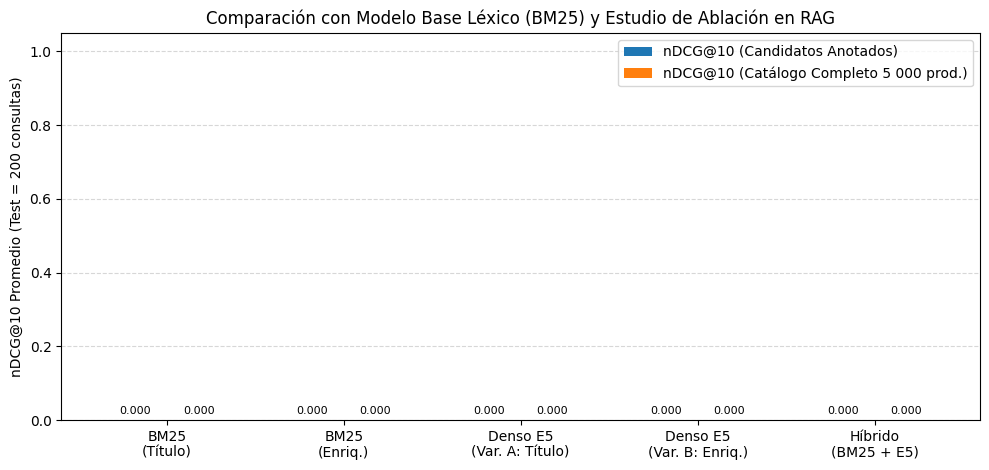


✓ Prueba de herramienta RAG (latencia: 30.25 ms):
  [1] ID: B07M8QVJQ3 | Precio: 43.67€ | Stock: 9 | Marca: HOMSCAM | Color: Negro | Título: Auriculares Bluetooth, HOMSCAM Auriculares inalámbricos Bluetooth...
  [2] ID: B07RSYFFLQ | Precio: 110.58€ | Stock: 5 | Marca: DYNASONIC | Color: Negro | Título: DYNASONIC - DY-65201 Altavoz Bluetooth Inalámbrico Sistema de Aud...
  [3] ID: B013OKA6YC | Precio: 89.41€ | Stock: 2 | Marca: wavemaster | Color: Negro | Título: Wavemaster STAX BT - 2.1 Sístema de Altavoces Activos (46 Vatios)...


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(results_df))
width = 0.36

bars1 = ax.bar(x - width / 2, results_df["_cand_val"], width, label="nDCG@10 (Candidatos Anotados)")
bars2 = ax.bar(x + width / 2, results_df["_full_val"], width, label="nDCG@10 (Catálogo Completo 5 000 prod.)")

ax.set_ylabel("nDCG@10 Promedio (Test = 200 consultas)")
ax.set_title("Comparación con Modelo Base Léxico (BM25) y Estudio de Ablación en RAG")
ax.set_xticks(x)
ax.set_xticklabels(["BM25\n(Título)", "BM25\n(Enriq.)", "Denso E5\n(Var. A: Título)", "Denso E5\n(Var. B: Enriq.)", "Híbrido\n(BM25 + E5)"], rotation=0)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

def retrieve_catalog_for_agent(query: str, store_instance: SimulatedStore, top_k: int = 5) -> Dict[str, Any]:
    """
    Herramienta RAG de recuperación para el agente conversacional.
    Cruza los productos recuperados con la tienda simulada y marca atributos faltantes como 'Desconocido'.
    """
    t0 = time.perf_counter()
    s_bm25 = min_max_normalize(bm25_enriched.get_scores(tokenize_es(query)))
    with torch.inference_mode():
        q_vec = embed_model.encode([f"query: {query}"], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)[0]
    s_dense = min_max_normalize(np.dot(embeddings_b, q_vec))
    s_hybrid = BEST_ALPHA * s_dense + (1.0 - BEST_ALPHA) * s_bm25

    top_pids = retrieve_top_k_from_scores(s_hybrid, top_k=top_k)
    results = []
    for rank_idx, pid in enumerate(top_pids, start=1):
        info = store_instance.get_product_info(pid)
        if info is not None:
            results.append({
                "rank": rank_idx,
                "product_id": info["product_id"],
                "title": info["title"],
                "brand": info["brand"],
                "color": info["color"],
                "price": info["price"],
                "stock": info["stock"],
                "bullet_point": info["bullet_point"][:250] if info["bullet_point"] != "Desconocido" else "Desconocido",
                "description": info["description"][:250] if info["description"] != "Desconocido" else "Desconocido",
                "score": round(float(s_hybrid[pid_to_idx[pid]]), 4)
            })

    elapsed_ms = round((time.perf_counter() - t0) * 1000, 2)
    return {"query": query, "latency_ms": elapsed_ms, "results": results}

# Ejemplo rápido de consulta RAG verificada
sample_rag_output = retrieve_catalog_for_agent("auriculares inalámbricos bluetooth con micrófono", store, top_k=3)
print(f"\n✓ Prueba de herramienta RAG (latencia: {sample_rag_output['latency_ms']} ms):")
for item in sample_rag_output["results"]:
    print(
        f"  [{item['rank']}] ID: {item['product_id']} | Precio: {item['price']}€ | Stock: {item['stock']} | "
        f"Marca: {item['brand']} | Color: {item['color']} | Título: {item['title'][:65]}..."
    )
